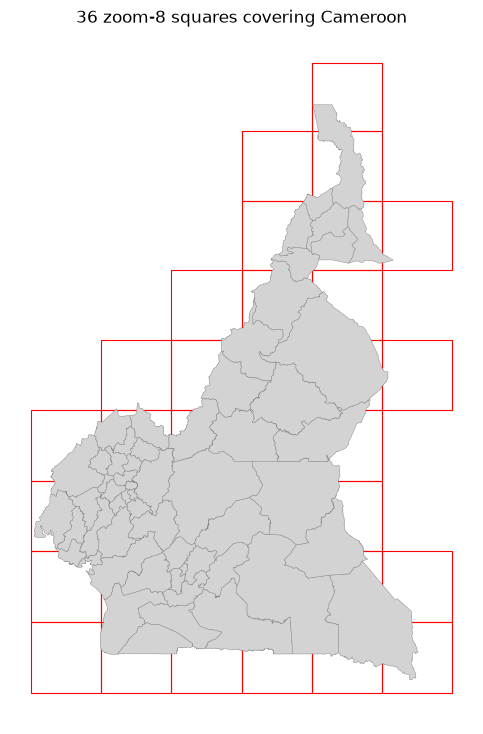

In [1]:
import json
from pathlib import Path
import geopandas as gpd
import mercantile
import matplotlib.pyplot as plt
from shapely.geometry import box

ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
INTERIM = ROOT / "data" / "interim"

dep = gpd.read_file(INTERIM / "departments.geojson")
quadkeys = json.load(open(INTERIM / "cameroon_quadkeys_z8.json", encoding="utf-8"))

squares = gpd.GeoDataFrame(
    {"quadkey": quadkeys},
    geometry=[box(*mercantile.bounds(mercantile.quadkey_to_tile(q))) for q in quadkeys],
    crs=4326,
)

fig, ax = plt.subplots(figsize=(8, 9))
squares.plot(ax=ax, facecolor="none", edgecolor="red", linewidth=0.8)
dep.plot(ax=ax, facecolor="lightgrey", edgecolor="grey", linewidth=0.3)
ax.set_title(f"{len(squares)} zoom-8 squares covering Cameroon")
ax.set_axis_off()
fig.savefig(ROOT / "reports" / "quadkey_filter.png", dpi=150, bbox_inches="tight")

In [ ]:
s